# 02. Scenario 1 — "My card doesn't swipe. What should I do?" (clarification loop)

The first support scenario. The inquiry **lacks specifics**, so the agent decides `need_clarification` at D5 (information sufficiency) and runs the recursive loop: **write a clarifying question -> receive the customer reply -> re-decide**.

Expected path:
```
D1(guardrail) -> D2(routing) -> D5(need_clarification) -> ask/reply -> D5(info_sufficient)
-> D3(tool choice) -> tool success -> D6(goal_met) -> summary -> D7(no_risk) -> D4(resolve) -> final reply
```

We run the same question once with **(1) Haiku decisions** and once with **(2) strands-decider decisions**, watching the STEP output, then compare the execution times at the end. (Reply generation is Sonnet 4.5 in both arms — only the decision layer differs.)


In [1]:
import os
os.environ["DMWS_LANG"] = "en"   # localize helper output/graph captions (set BEFORE importing ws_common)
import sys; from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # ws_common path (relative inside the repo)
import ws_common as W
graphs, client = W.make_graphs()
sc = W.scenario(1)
print("Scenario:", sc["title"])
print("Customer question:", sc["question"])
print("script (pre-set for reproducibility):", sc["script"])


Scenario: Vague inquiry -> clarification loop
Customer question: My card doesn't swipe. What should I do?
script (pre-set for reproducibility): {'vague': True, 'clarify_reply': "Since yesterday the card won't go through at in-store terminals only. Details: Visa debit card ending 7712, last attempt on 2026-10-27 at TechMart Gangnam, amount USD 34.60.", 'no_info_reply': "That's all the information I have right now.", 'tool_outcomes': ['success'], 'risk_flag': False, 'kyc_result': None}


## Where this scenario sits in the full workflow

The path this scenario takes (red borders): intake screening -> routing -> **clarification loop (clarify_gate <-> ask_clarify)** -> one successful tool call -> summary -> no risk -> resolve. The KYC sub-flow and the give_up path are not visited this time.

Assigned team (red box): **declined_pay (declined/pending pay)** — in English, "my card doesn't swipe / won't go through" reads as a payment being declined, so D2 routes there. (The Korean phrasing of the same scenario routes to the **cards** team in the [KR] notebook — routing is wording-sensitive, which is itself worth observing.) Compare with the actual D2 decision in the STEP output.
> Note: this diagram is not auto-generated from the running LangGraph; it is a **visualization-only drawing** rendered from the caption dictionaries in `ws_common.py`, keyed by node name (details: `[EN]_01_build_agent.ipynb`).


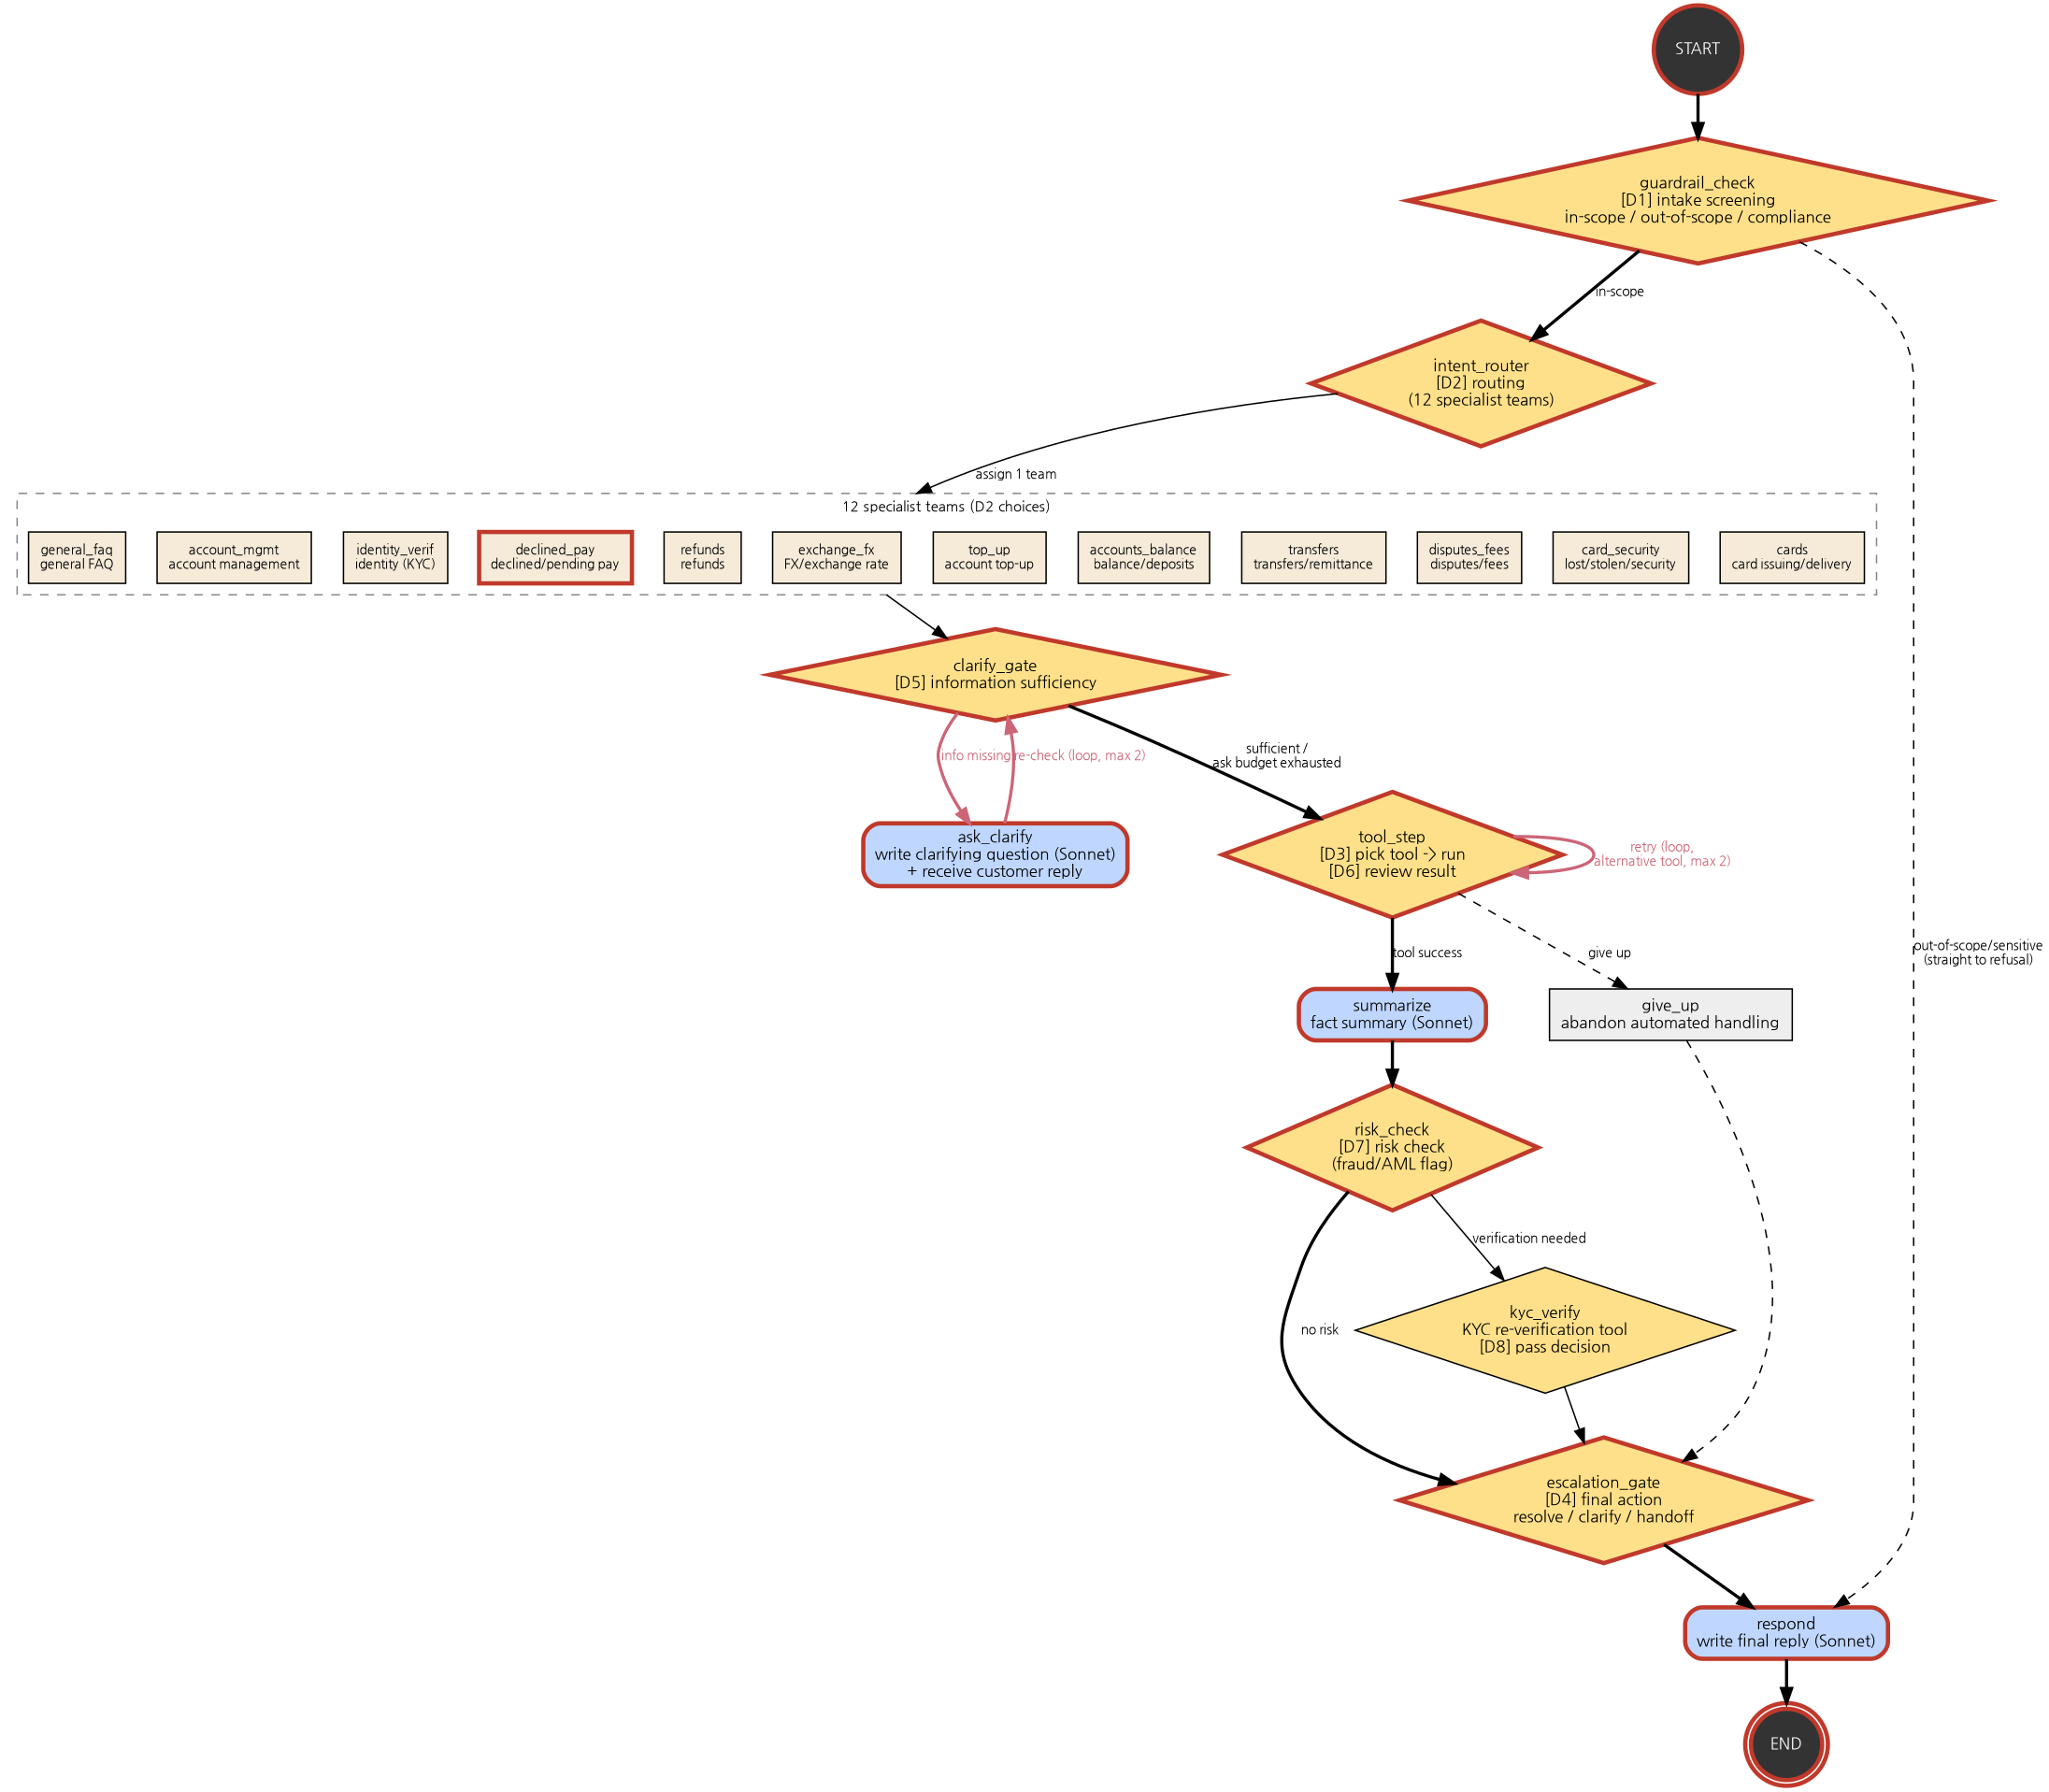

In [2]:
W.draw_graph(highlight=W.scenario_path(1), show_teams=True, width=760)

## (1) Run with the Haiku 4.5 decision agent

Each STEP prints which node makes which decision (label) in how many ms, plus the clarifying question, the customer reply and the final answer. Note that **every single decision takes 600ms or more**.


In [3]:
res_haiku = W.run_verbose(graphs["Haiku"], sc["question"], sc["script"], "Haiku")


[Haiku] customer: My card doesn't swipe. What should I do?



STEP 1 ▶ guardrail_check — D1 intake screening: in-scope / out-of-scope / compliance
      decision[D1] -> in_scope   (756ms)



STEP 2 ▶ intent_router — D2 routing: pick one of 12 specialist teams
      decision[D2] -> cards   (521ms)



STEP 3 ▶ clarify_gate — D5 sufficiency check: can we act now, or must we ask back?
      decision[D5] -> need_clarification   (574ms)



STEP 4 ▶ ask_clarify — Clarify: Sonnet writes a question -> customer reply received
      generate(sonnet-4-5)   (1,160ms)
      support agent: Which card are you having trouble with - your debit card or credit card?
      customer: Since yesterday the card won't go through at in-store terminals only. Details: Visa debit card ending 7712, last attempt on 2026-10-27 at TechMart Gangnam, amount USD 34.60.



STEP 5 ▶ clarify_gate — D5 sufficiency check: can we act now, or must we ask back?
      decision[D5] -> info_sufficient   (540ms)



STEP 6 ▶ tool_step — D3 tool choice -> run tool -> D6 result review (done/retry/give up)
      decision[D3] -> card_troubleshoot   (530ms)
      tool run: card_troubleshoot   (0.0ms)
      decision[D6] -> goal_met   (498ms)



STEP 7 ▶ summarize — Sonnet condenses the tool result into customer-facing facts
      generate(sonnet-4-5)   (2,259ms)
      summary (first line): Based on the tool result, here are the key resolution facts:



STEP 8 ▶ risk_check — D7 risk check: fraud/AML monitoring flag present?
      decision[D7] -> no_risk   (512ms)



STEP 9 ▶ escalation_gate — D4 final action: resolve / clarify / human handoff
      decision[D4] -> resolve   (510ms)



STEP 10 ▶ respond — Sonnet writes the final customer reply
      generate(sonnet-4-5)   (2,508ms)
      --- final reply ---
      Thank you for providing those details. I've successfully run a troubleshooting operation on your Visa debit card ending in 7712 (Reference: REF-ws-Haiku-286110).
      
      Please try using your card again at an in-store terminal. The issue should now be resolved. If you continue to experience problems with card swipes after this, please contact us immediately at our 24/7 helpline, and we'll arrange a card replacement for you.
      
      Is there anything else I can help you with today?

>>> [Haiku] 8 decisions, total 4,441ms | generation 5,928ms | e2e 10,378ms


## (2) Run with strands-decider (E4B) decisions

Same graph, same question. The difference: each decision finishes in a single local forward pass — no LLM round-trip — and comes with a **confidence**.


In [4]:
res_strands = W.run_verbose(graphs["StrandsDecider"], sc["question"], sc["script"], "StrandsDecider")


[StrandsDecider] customer: My card doesn't swipe. What should I do?

STEP 1 ▶ guardrail_check — D1 intake screening: in-scope / out-of-scope / compliance
      decision[D1] -> in_scope   (125ms, confidence 0.972)



STEP 2 ▶ intent_router — D2 routing: pick one of 12 specialist teams
      decision[D2] -> cards   (105ms, confidence 0.799)

STEP 3 ▶ clarify_gate — D5 sufficiency check: can we act now, or must we ask back?
      decision[D5] -> need_clarification   (105ms, confidence 0.628)



STEP 4 ▶ ask_clarify — Clarify: Sonnet writes a question -> customer reply received
      generate(sonnet-4-5)   (1,187ms)
      support agent: Which card are you having trouble with - your debit card or credit card?
      customer: Since yesterday the card won't go through at in-store terminals only. Details: Visa debit card ending 7712, last attempt on 2026-10-27 at TechMart Gangnam, amount USD 34.60.

STEP 5 ▶ clarify_gate — D5 sufficiency check: can we act now, or must we ask back?
      decision[D5] -> info_sufficient   (106ms, confidence 0.739)



STEP 6 ▶ tool_step — D3 tool choice -> run tool -> D6 result review (done/retry/give up)
      decision[D3] -> card_troubleshoot   (102ms, confidence 0.990)
      tool run: card_troubleshoot   (0.0ms)
      decision[D6] -> goal_met   (102ms, confidence 0.749)



STEP 7 ▶ summarize — Sonnet condenses the tool result into customer-facing facts
      generate(sonnet-4-5)   (1,972ms)
      summary (first line): Based on the tool result, here are the key resolution facts:

STEP 8 ▶ risk_check — D7 risk check: fraud/AML monitoring flag present?
      decision[D7] -> no_risk   (153ms, confidence 0.961)



STEP 9 ▶ escalation_gate — D4 final action: resolve / clarify / human handoff
      decision[D4] -> resolve   (155ms, confidence 0.954)



STEP 10 ▶ respond — Sonnet writes the final customer reply
      generate(sonnet-4-5)   (2,109ms)
      --- final reply ---
      Good news! I've successfully resolved the technical issue with your Visa debit card ending in 7712. The card should now work properly at in-store terminals.
      
      Please try using your card again at any merchant terminal. If you continue to experience any issues, please don't hesitate to contact us immediately.
      
      Reference number for your records: REF-ws-StrandsDecider-286121
      
      Is there anything else I can help you with today?

>>> [StrandsDecider] 8 decisions, total 954ms | generation 5,268ms | e2e 6,231ms


## (3) Execution time comparison

Generation (Sonnet) time is similar on both sides — the point is that **the decision layer's share of time disappears almost entirely**.


In [5]:
W.compare(res_haiku, res_strands)

| metric | Haiku | StrandsDecider | ratio(Haiku/StrandsDecider) |
|---|---:|---:|---:|
| decisions | 8 | 8 | |
| **decision latency total** | **4,441ms** | **954ms** | **4.7x** |
| generation (LLM) latency | 5,928ms | 5,268ms | **1.1x** |
| e2e | 10,378ms | 6,231ms | **1.7x** |

**decision-layer speedup: 4.7x** (e2e saved 4,147ms)

**per-decision latency**

| node | decision | Haiku | StrandsDecider | ratio | label |
|---|---|---:|---:|---:|---|
| guardrail_check | D1 | 756ms | 125ms | **6.1x** | in_scope (same) |
| intent_router | D2 | 521ms | 105ms | **4.9x** | cards (same) |
| clarify_gate | D5 | 574ms | 105ms | **5.5x** | need_clarification (same) |
| clarify_gate | D5 | 540ms | 106ms | **5.1x** | info_sufficient (same) |
| tool_select | D3 | 530ms | 102ms | **5.2x** | card_troubleshoot (same) |
| tool_review | D6 | 498ms | 102ms | **4.9x** | goal_met (same) |
| risk_check | D7 | 512ms | 153ms | **3.3x** | no_risk (same) |
| escalation_gate | D4 | 510ms | 155ms | **3.3x** | resolve (same) |

**What to look for**
- D5 runs twice because of the clarification loop — the more the loop runs, the more decisions pile up, and the bigger the cumulative gap for a slow decision backend.
- Compare whether both arms produced the same labels (rightmost column of the table). If they match, this conversation gained speed with no quality loss.
- Next: `[EN]_03_scenario2_retry.ipynb` — the loop where the agent recovers on its own when a tool fails.
